# ImmoAnalyse — exploration et contrôle qualité

**Projet fil rouge du Module 1 : Python pour l'IA et le Machine Learning**

Ce notebook présente, à partir des fichiers produits par le pipeline (`python -m src.main`) :

1. la qualité des données reçues et le sort de chaque enregistrement ;
2. les anomalies détectées, les corrections et les doublons ;
3. les distributions des prix et des surfaces, avant et après nettoyage ;
4. les résultats par type de bien et par ville ;
5. les conclusions et les limites.

> **Prérequis** : lancer d'abord `python -m src.main` depuis la racine du projet. Ce notebook ne modifie aucune donnée : il lit `data/processed/`, `data/quarantine/` et `reports/`.
>
> **Avertissement** : données synthétiques, prix demandés (annonces) et non prix de transaction. Aucune conclusion sur le marché réel.

## 0. Préparation

In [2]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Le notebook se trouve dans notebooks/ : on remonte à la racine du projet
RACINE = Path.cwd().resolve()
if RACINE.name == "notebooks":
    RACINE = RACINE.parent
os.chdir(RACINE)
sys.path.insert(0, str(RACINE))

from src.analysis.statistiques import (
    loyers_mensuels, resume_loyers_par, resume_ventes_par, statistiques, ventes,
)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".rstrip("0").rstrip("."))
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Environnement prêt : pandas", pd.__version__)

Environnement prêt : pandas 3.1.0


In [3]:
rapport = json.loads((RACINE / "reports" / "quality_report.json").read_text(encoding="utf-8"))
propres = pd.read_csv(RACINE / "data" / "processed" / "biens_propres.csv", dtype={"id_local": str})
quarantaine = pd.read_csv(RACINE / "data" / "quarantine" / "quarantaine.csv")
journal = pd.read_csv(RACINE / "reports" / "journal_normalisation.csv")
violations = pd.read_csv(RACINE / "reports" / "violations.csv")
liens = pd.read_csv(RACINE / "reports" / "liens_doublons.csv")

print(f"Date d'exécution du pipeline : {rapport['date_execution']}")
print(f"Enregistrements reçus : {rapport['total_recus']}")
print(f"Biens propres : {len(propres)} | quarantaine et doublons écartés : {len(quarantaine)}")

Date d'exécution du pipeline : 2026-10-29
Enregistrements reçus : 3184
Biens propres : 2983 | quarantaine et doublons écartés : 201


## 1. Qualité globale : que devient chaque enregistrement ?

Chaque enregistrement est compté **une seule fois**, dans une seule catégorie (priorité : doublon écarté, puis quarantaine, puis avertissement, puis entièrement conforme).

,enregistrements,part_%
Entièrement conformes,2589,81.31
Conservés avec avertissement,394,12.37
Quarantaine,186,5.84
Doublons écartés,15,0.47
Total,3184,100


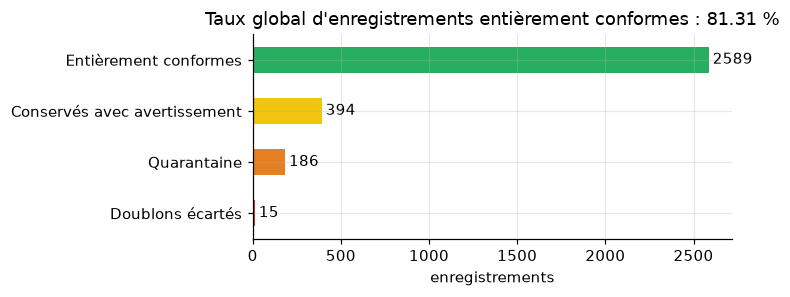

In [4]:
e = rapport["enregistrements"]
classement = pd.Series({
    "Entièrement conformes": e["entierement_conformes"],
    "Conservés avec avertissement": e["conserves_avec_avertissement"],
    "Quarantaine": e["quarantaine"],
    "Doublons écartés": e["doublons_ecartes"],
})
tableau = classement.to_frame("enregistrements")
tableau["part_%"] = (100 * classement / rapport["total_recus"]).round(2)
tableau.loc["Total"] = [classement.sum(), 100.0]
display(tableau)
assert classement.sum() == rapport["total_recus"], "un enregistrement a été perdu ou compté deux fois"

fig, ax = plt.subplots(figsize=(7, 2.8))
classement[::-1].plot.barh(ax=ax, color=["#c0392b", "#e67e22", "#f1c40f", "#27ae60"])
for i, v in enumerate(classement[::-1]):
    ax.text(v + 20, i, f"{v}", va="center")
ax.set_xlabel("enregistrements")
ax.set_title(f"Taux global d'enregistrements entièrement conformes : {rapport['taux_global_entierement_conformes_pct']} %")
plt.tight_layout()
plt.show()

classement,conserve_avec_avertissement,doublon_ecarte,entierement_conforme,quarantaine,total
source,,,,,
historique,62,0,456,10,528
notaires,2,0,388,20,410
particuliers,203,0,396,132,731
plateforme,0,15,845,15,875
teranga,127,0,504,9,640


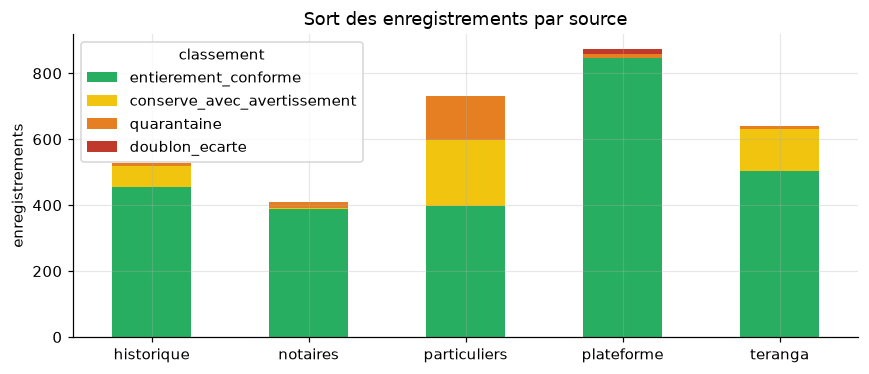

In [5]:
par_source = pd.concat([
    propres.groupby(["source", "classement"]).size(),
    quarantaine.groupby(["source", "classement"]).size(),
]).unstack(fill_value=0)
par_source["total"] = par_source.sum(axis=1)
display(par_source)

ordre = ["entierement_conforme", "conserve_avec_avertissement", "quarantaine", "doublon_ecarte"]
couleurs = ["#27ae60", "#f1c40f", "#e67e22", "#c0392b"]
ax = par_source[ordre].plot.bar(stacked=True, color=couleurs, figsize=(8, 3.5))
ax.set_title("Sort des enregistrements par source")
ax.set_xlabel("")
ax.set_ylabel("enregistrements")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 2. Taux de conformité par règle

`taux de conformité = conformes / évaluables × 100`. Les enregistrements **non évaluables** (par exemple le prix au m² d'une location) sont comptés à part et ne sont jamais considérés comme conformes. Les règles `B` sont bloquantes (quarantaine), les règles `A` sont des avertissements.

,code,regle,gravite,evaluables,conformes,non_conformes,non_evaluables,taux_conformite
0,B01,Identifiant local présent,bloquante,3184,3184,0,0,100
1,B02,Type de transaction interprétable,bloquante,3184,3182,2,0,99.94
2,B03,Prix numérique strictement positif,bloquante,3184,3086,98,0,96.92
3,B04,Surface numérique strictement positive,bloquante,3184,3100,84,0,97.36
4,B05,Date interprétable,bloquante,3184,3178,6,0,99.81
5,B06,Date non future (par rapport à l'exécution),bloquante,3178,3173,5,6,99.84
6,B07,Type de bien dans le référentiel,bloquante,3184,3184,0,0,100
7,A01,Surface non atypique,avertissement,3100,3100,0,84,100
8,A02,Prix de vente non atypique,avertissement,2608,2608,0,576,100
9,A03,Loyer mensuel non atypique,avertissement,177,177,0,3007,100


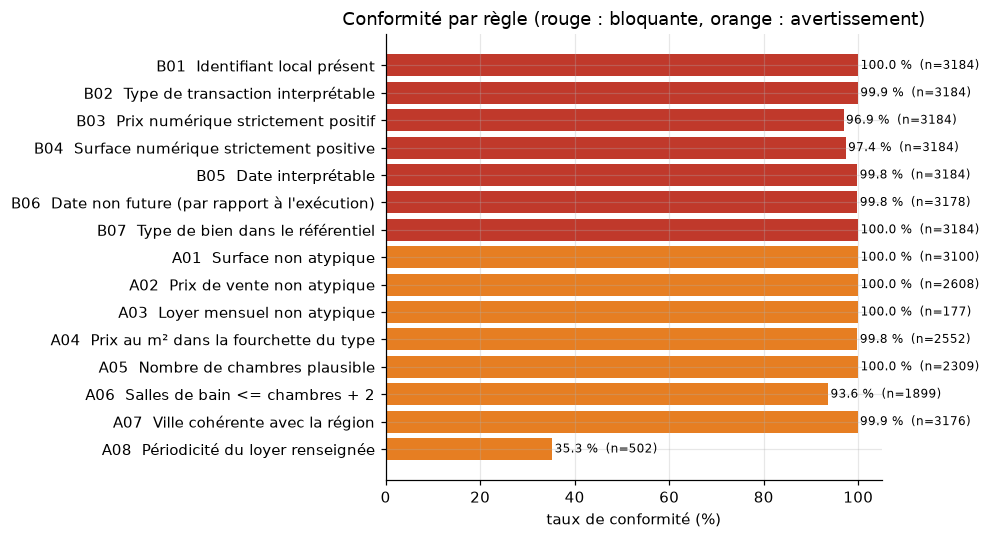

In [6]:
regles = pd.DataFrame(rapport["regles"])
display(regles[["code", "regle", "gravite", "evaluables", "conformes", "non_conformes",
                "non_evaluables", "taux_conformite"]])

r = regles.dropna(subset=["taux_conformite"]).iloc[::-1]
couleurs = r["gravite"].map({"bloquante": "#c0392b", "avertissement": "#e67e22"})
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(r["code"] + "  " + r["regle"], r["taux_conformite"], color=couleurs)
ax.set_xlim(0, 105)
for i, (t, n) in enumerate(zip(r["taux_conformite"], r["evaluables"])):
    ax.text(t + 0.5, i, f"{t:.1f} %  (n={n})", va="center", fontsize=8)
ax.set_xlabel("taux de conformité (%)")
ax.set_title("Conformité par règle (rouge : bloquante, orange : avertissement)")
plt.tight_layout()
plt.show()

## 3. Anomalies détectées

### 3.1 Valeurs manquantes

Les colonnes **absentes par construction** (par exemple `chambres` pour la plateforme, qui fournit `pieces`) ne sont pas des valeurs manquantes : elles sont non évaluables et marquées `NaN` ci-dessous.

Valeurs manquantes réelles par colonne et par source (NaN = colonne non fournie par la source)


,historique,notaires,particuliers,plateforme,teranga
ville,8,0,0,0,0
prix,10,14,61,0,0
surface,0,0,75,5,0
description,NaN,NaN,NaN,165,NaN


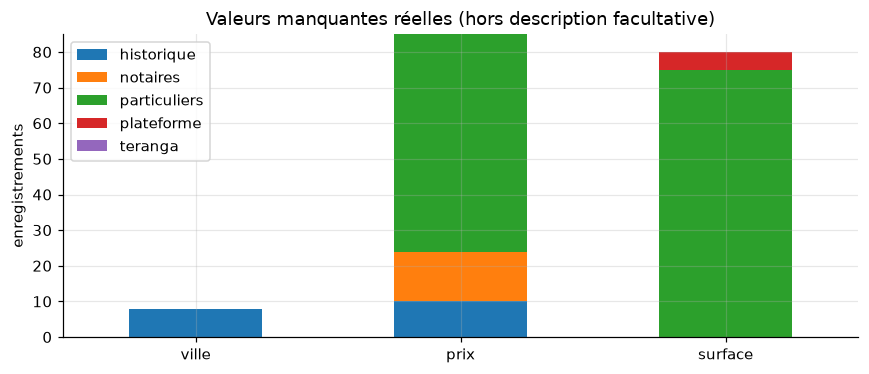

In [7]:
manq = pd.DataFrame({c: v["par_source"] for c, v in rapport["valeurs_manquantes"].items()}).T.astype(float)
for absente in rapport["colonnes_absentes_par_construction"]:
    source, colonne = absente.split(".", 1)
    manq.loc[colonne, source] = np.nan
print("Valeurs manquantes réelles par colonne et par source (NaN = colonne non fournie par la source)")
display(manq.loc[manq.fillna(0).sum(axis=1) > 0])

reelles = manq.fillna(0)
reelles = reelles.loc[reelles.sum(axis=1) > 0].drop(index="description", errors="ignore")
ax = reelles.plot.bar(stacked=True, figsize=(8, 3.5))
ax.set_title("Valeurs manquantes réelles (hors description facultative)")
ax.set_ylabel("enregistrements")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3.2 Erreurs de conversion et corrections par champ

statut,ambigu,corrige,invalide,manquant
champ,,,,
date,0,959,6,0
periodicite,0,177,0,0
prix,0,142,11,87
surface,0,83,4,80
type_bien,0,157,0,0
type_transaction,2,1576,0,0
ville,0,12,0,8


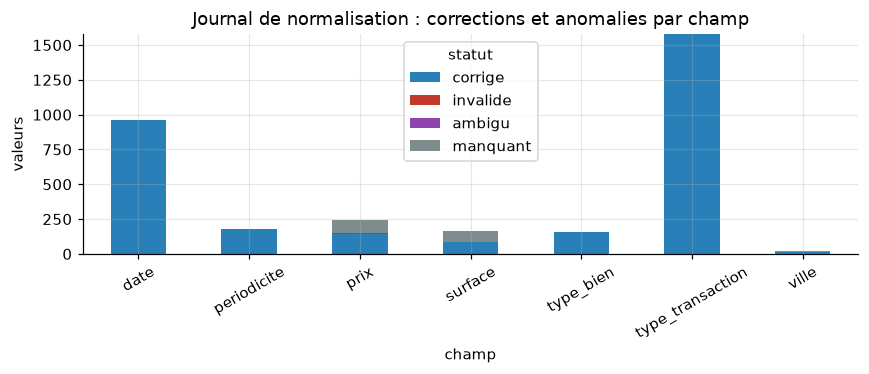

Erreurs de conversion (invalide + ambigu) : {'date': 6, 'prix': 11, 'surface': 4, 'type_transaction': 2}
Exemples de corrections de prix :


,source,valeur_brute,valeur_normalisee,motif
0,plateforme,57.62 millions,57620000,unité « millions » explicite
3,plateforme,438 746 000,438746000,espaces comme séparateurs de milliers
1253,particuliers,65575000 FCFA,65575000,suffixe FCFA retiré


In [8]:
resume = journal.groupby(["champ", "statut"]).size().unstack(fill_value=0)
display(resume)

colonnes = [c for c in ["corrige", "invalide", "ambigu", "manquant", "hors_referentiel"] if c in resume.columns]
ax = resume[colonnes].plot.bar(stacked=True, figsize=(8, 3.5),
                               color=["#2980b9", "#c0392b", "#8e44ad", "#7f8c8d", "#16a085"][:len(colonnes)])
ax.set_title("Journal de normalisation : corrections et anomalies par champ")
ax.set_ylabel("valeurs")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Erreurs de conversion (invalide + ambigu) :", rapport["erreurs_conversion_par_champ"])
print("Exemples de corrections de prix :")
display(journal[(journal.champ == "prix") & (journal.statut == "corrige")]
        [["source", "valeur_brute", "valeur_normalisee", "motif"]].drop_duplicates("motif").head(6))

### 3.3 Pourquoi des enregistrements partent-ils en quarantaine ?

source,historique,notaires,particuliers,plateforme,teranga
code,,,,,
B02,0,0,0,0,2
B03,10,14,63,6,5
B04,0,0,75,5,4
B05,0,6,0,0,0
B06,0,0,0,5,0


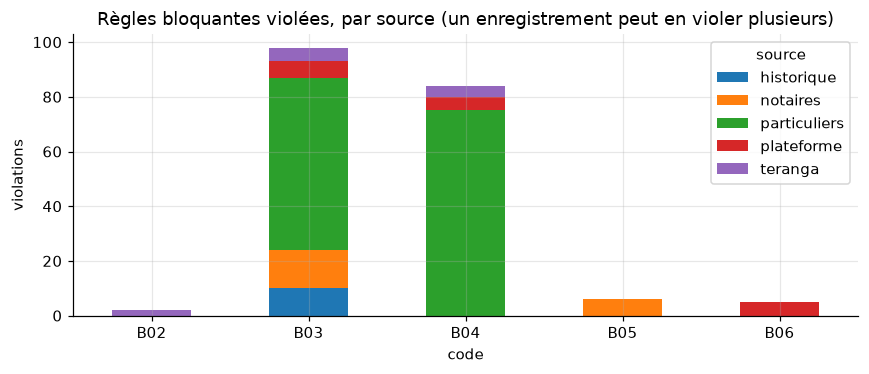

Exemples de motifs en quarantaine :


,source,id_local,classement,motifs,brut_date,brut_prix,brut_surface
0,plateforme,PLT-00014,quarantaine,B06: date future (2028-12-01),2028-12-01,91358000,111.6
1,plateforme,PLT-00062,quarantaine,B03: prix invalide,2023-04-04,à négocier,1131.9
2,plateforme,PLT-00077,quarantaine,B06: date future (2028-12-01),2028-12-01,64862000,78.4
3,plateforme,PLT-00085,quarantaine,B03: prix invalide,2025-11-11,à négocier,163.7
4,plateforme,PLT-00211,quarantaine,B04: surface manquant,2020-08-07,595000,NaN
5,plateforme,PLT-00222,quarantaine,B03: prix invalide,2019-06-25,à négocier,55.1
6,plateforme,PLT-00249,quarantaine,B04: surface manquant,2022-04-18,162813000,NaN
7,plateforme,PLT-00395,quarantaine,B06: date future (2028-12-01),2028-12-01,64427000,701.4


In [9]:
bloquantes = violations[violations["gravite"] == "bloquante"]
motifs = bloquantes.groupby(["code", "source"]).size().unstack(fill_value=0)
display(motifs)
ax = motifs.plot.bar(stacked=True, figsize=(8, 3.5))
ax.set_title("Règles bloquantes violées, par source (un enregistrement peut en violer plusieurs)")
ax.set_ylabel("violations")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Exemples de motifs en quarantaine :")
display(quarantaine[["source", "id_local", "classement", "motifs", "brut_date", "brut_prix", "brut_surface"]].head(8))

### 3.4 Avertissements (enregistrements conservés)

Ces anomalies sont signalées dans la colonne `avertissements` des données propres, sans exclure le bien.

In [10]:
avert = violations[violations["gravite"] == "avertissement"].groupby("code").size().rename("violations")
noms = regles.set_index("code")["regle"]
display(pd.concat([avert, noms.reindex(avert.index)], axis=1))

,violations,regle
code,,
A04,4,Prix au m² dans la fourchette du type
A06,121,Salles de bain <= chambres + 2
A07,4,Ville cohérente avec la région
A08,325,Périodicité du loyer renseignée


### 3.5 Doublons et conflits

Un **doublon exact** a le même identifiant dans la même source et les mêmes valeurs ; sa copie est écartée. Les doublons probables et les conflits sont signalés, **jamais fusionnés**.

In [11]:
print(rapport["doublons"])
display(liens["type_lien"].value_counts().to_frame("liens"))
display(liens.head(5))

{'exacts': 15, 'taux_exacts_pct': 0.47, 'probables': 0, 'conflits_identifiant': 0, 'conflits_prix': 0}


,liens
type_lien,
doublon_exact,15


,id_a,id_b,source_a,source_b,id_local_a,id_local_b,type_lien,motif
0,57,864,plateforme,plateforme,PLT-00058,PLT-00058,doublon_exact,mêmes identifiant et valeurs
1,170,869,plateforme,plateforme,PLT-00171,PLT-00171,doublon_exact,mêmes identifiant et valeurs
2,397,867,plateforme,plateforme,PLT-00398,PLT-00398,doublon_exact,mêmes identifiant et valeurs
3,490,873,plateforme,plateforme,PLT-00491,PLT-00491,doublon_exact,mêmes identifiant et valeurs
4,493,871,plateforme,plateforme,PLT-00494,PLT-00494,doublon_exact,mêmes identifiant et valeurs


## 4. Distributions des ventes (données propres)

Les ventes et les locations sont **toujours analysées séparément** : un loyer de 250 000 FCFA n'est pas comparable à un prix de vente de 250 000 FCFA. Les prix en FCFA couvrant plusieurs ordres de grandeur, on utilise une échelle logarithmique.

2531 ventes exploitables sur 2983 biens propres


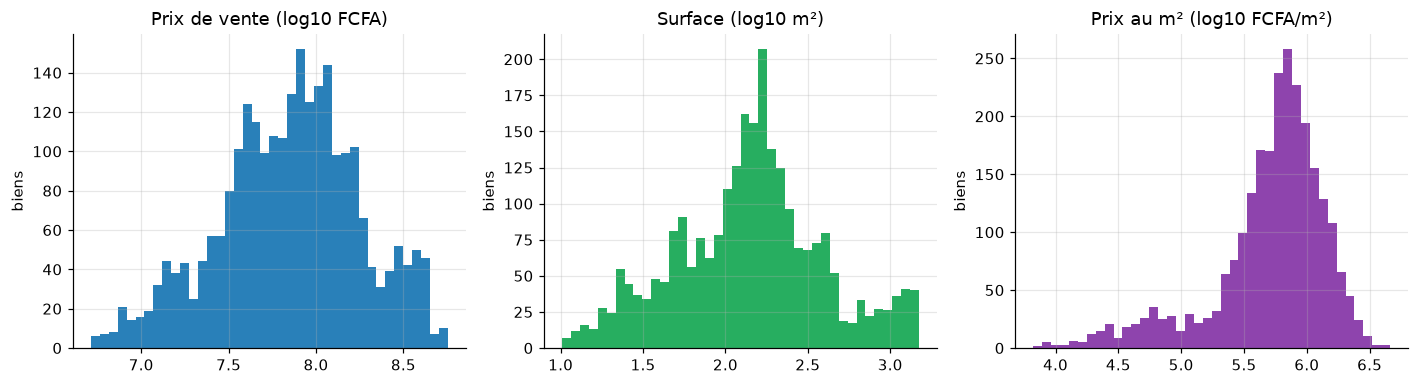

,prix_vente,prix_m2,surface
n,"2,531","2,531","2,531"
moyenne,"104,634,635.48","736,798.91",236.31
mediane,"74,982,000","626,812.44",146.9
ecart_type,"98,293,307.3","562,131.76",285.28
min,"5,156,000","6,647.91",10.2
q1,"38,819,500","353,674.34",70.95
q3,"129,876,500","979,544.97",246.95
max,"567,559,000","4,603,187.77","1,494.8"


In [12]:
v = ventes(propres)
print(f"{len(v)} ventes exploitables sur {len(propres)} biens propres")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].hist(np.log10(v["prix"]), bins=40, color="#2980b9")
axes[0].set_title("Prix de vente (log10 FCFA)")
axes[1].hist(np.log10(v["surface"]), bins=40, color="#27ae60")
axes[1].set_title("Surface (log10 m²)")
axes[2].hist(np.log10(v["prix_m2"]), bins=40, color="#8e44ad")
axes[2].set_title("Prix au m² (log10 FCFA/m²)")
for ax in axes:
    ax.set_ylabel("biens")
plt.tight_layout()
plt.show()

stats = pd.DataFrame({"prix_vente": statistiques(v["prix"]), "prix_m2": statistiques(v["prix_m2"]),
                      "surface": statistiques(v["surface"])})
display(stats)

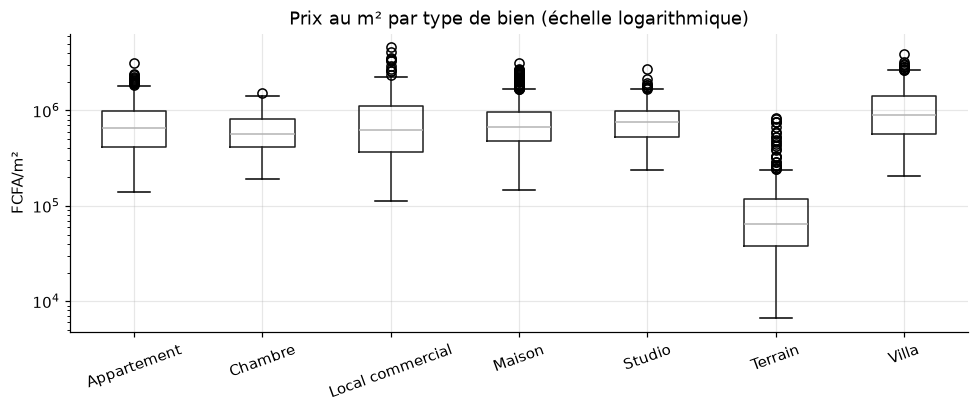

In [13]:
ordre = v.groupby("type_bien")["prix_m2"].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 4))
v.boxplot(column="prix_m2", by="type_bien", ax=ax, rot=20)
ax.set_yscale("log")
ax.set_title("Prix au m² par type de bien (échelle logarithmique)")
ax.set_ylabel("FCFA/m²")
ax.set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()

## 5. Effet du nettoyage sur les statistiques

On compare une lecture **naïve** des données brutes (conversion numérique directe, ventes et locations mélangées) à la lecture **après pipeline** (valeurs normalisées, ventes séparées des locations).

,"avant (lecture naïve, tout mélangé)",après (ventes normalisées)
n,"2,944","2,531"
moyenne,"88,237,358.49","104,634,635.48"
mediane,"59,578,000","74,982,000"
ecart_type,"97,663,875.95","98,293,307.3"
min,"40,000","5,156,000"
q1,"21,521,500","38,819,500"
q3,"116,036,000","129,876,500"
max,"567,559,000","567,559,000"


Prix lisibles : avant 2944 sur 3184 enregistrements, après 2531 ventes exploitables


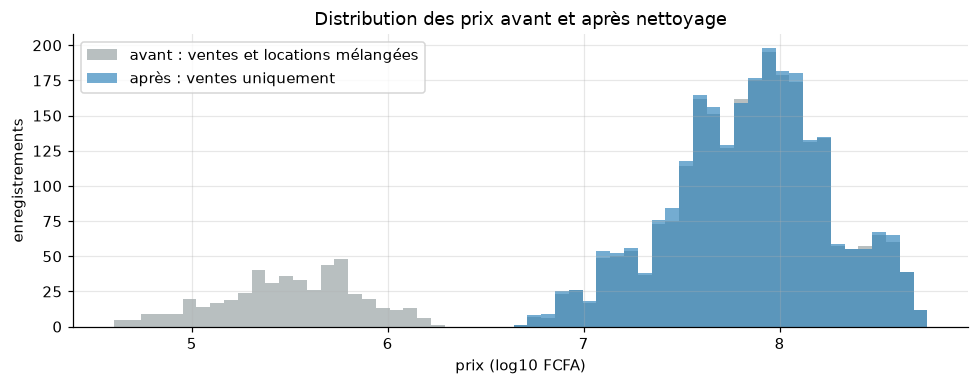

In [14]:
from src.loaders.harmonisation import charger_toutes_les_sources

brut = charger_toutes_les_sources()
avant = pd.to_numeric(brut["prix"], errors="coerce").dropna()
avant = avant[avant > 0]
apres = v["prix"]

comparaison = pd.DataFrame({"avant (lecture naïve, tout mélangé)": statistiques(avant),
                            "après (ventes normalisées)": statistiques(apres)})
display(comparaison)
print(f"Prix lisibles : avant {len(avant)} sur {len(brut)} enregistrements, après {len(apres)} ventes exploitables")

fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.linspace(np.log10(avant.min()), np.log10(avant.max()), 60)
ax.hist(np.log10(avant), bins=bins, alpha=0.55, color="#7f8c8d", label="avant : ventes et locations mélangées")
ax.hist(np.log10(apres), bins=bins, alpha=0.65, color="#2980b9", label="après : ventes uniquement")
ax.set_xlabel("prix (log10 FCFA)")
ax.set_ylabel("enregistrements")
ax.set_title("Distribution des prix avant et après nettoyage")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Résultats par type de bien

,type_bien,n,prix_median,prix_moyen,prix_m2_median,surface_mediane,effectif_fiable
0,Appartement,590,"70,161,500","73,332,205.08","656,660.7",110.05,True
1,Maison,535,"103,753,000","107,988,616.82","670,797.59",157,True
2,Villa,448,"266,046,000","265,992,558.04","906,133.25",297.35,True
3,Terrain,355,"48,825,000","50,052,284.51","64,764.93",766.3,True
4,Studio,302,"29,187,000","29,563,752.98","748,130.58",39.15,True
5,Chambre,157,"11,739,000","11,790,554.14","571,791.91",19.6,True
6,Local commercial,144,"106,482,000","111,651,069.44","625,690.72",177.75,True


Loyers mensuels comparables : 171 sur 452 locations (seule la plateforme fournit la périodicité ; elle n'est jamais devinée)


,type_bien,n,loyer_median,loyer_moyen,effectif_fiable
0,Appartement,53,"370,000","367,264.15",True
1,Maison,31,"545,000","515,000",True
2,Terrain,29,"160,000","167,758.62",True
3,Studio,23,"160,000","159,347.83",True
4,Villa,21,"850,000","930,238.1",True
5,Chambre,8,"70,000","68,125",True
6,Local commercial,6,"592,500","592,500",True


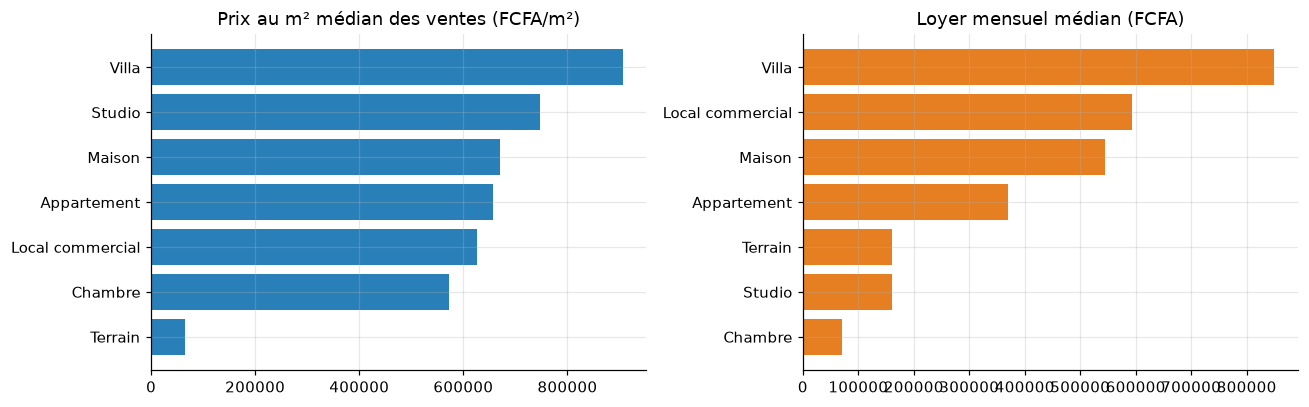

In [15]:
par_type = resume_ventes_par(v, "type_bien")
display(par_type)

l = loyers_mensuels(propres)
loyers_type = resume_loyers_par(l, "type_bien")
print(f"Loyers mensuels comparables : {len(l)} sur {(propres['type_transaction'] == 'location').sum()} locations "
      "(seule la plateforme fournit la périodicité ; elle n'est jamais devinée)")
display(loyers_type)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
p = par_type.sort_values("prix_m2_median")
axes[0].barh(p["type_bien"], p["prix_m2_median"], color="#2980b9")
axes[0].set_title("Prix au m² médian des ventes (FCFA/m²)")
q = loyers_type.sort_values("loyer_median")
axes[1].barh(q["type_bien"], q["loyer_median"], color="#e67e22")
axes[1].set_title("Loyer mensuel médian (FCFA)")
plt.tight_layout()
plt.show()

## 7. Résultats par ville

On ne retient que les villes dont l'effectif est fiable (au moins 5 ventes). Attention : les différences entre villes sont à interpréter avec prudence, les données étant synthétiques.

In [16]:
par_ville = resume_ventes_par(v, "ville")
fiables = par_ville[par_ville["effectif_fiable"]]
print(f"{len(fiables)} villes fiables sur {len(par_ville)}")
print("\nPrix au m² médian le plus élevé :")
display(fiables.nlargest(8, "prix_m2_median")[["ville", "n", "prix_median", "prix_m2_median", "surface_mediane"]])
print("Prix au m² médian le plus bas :")
display(fiables.nsmallest(8, "prix_m2_median")[["ville", "n", "prix_median", "prix_m2_median", "surface_mediane"]])

print("Dispersion du prix au m² médian entre villes :")
display(fiables["prix_m2_median"].describe().to_frame().T)

46 villes fiables sur 46

Prix au m² médian le plus élevé :


,ville,n,prix_median,prix_m2_median,surface_mediane
38,Dakar,44,"91,518,000","1,021,545.53",158.5
24,Rufisque,54,"118,121,500","807,319.68",154.05
41,Pikine,42,"102,607,500","780,854.54",143.35
22,Saint-Louis,55,"92,359,000","723,157.18",122.9
1,Ourossogui,69,"69,709,000","707,204.61",120.1
37,Touba,45,"77,142,000","706,127.27",155.5
23,Kolda,55,"72,247,000","704,725.46",134.9
34,Birkelane,46,"68,469,500","697,893.18",138.6


Prix au m² médian le plus bas :


,ville,n,prix_median,prix_m2_median,surface_mediane
45,Keur Massar,29,"51,400,000","469,529.29",161.9
2,Ziguinchor,69,"53,433,000","508,004.56",123.6
29,Oussouye,52,"84,031,500","523,524.34",173.15
31,Tambacounda,52,"69,215,500","540,960.88",167.05
18,Bakel,56,"69,774,500","555,023.45",140.45
5,Kanel,67,"79,370,000","556,675.26",161.3
19,Fatick,56,"74,256,500","559,660.35",170.35
21,Mbacké,55,"70,303,000","564,668.4",147


Dispersion du prix au m² médian entre villes :


,count,mean,std,min,25%,50%,75%,max
prix_m2_median,46,"636,650.42","88,382.11","469,529.29","591,672.09","619,028.73","670,972.87","1,021,545.53"


## 8. Conclusions

### Qualité des données

- Sur **3 184 enregistrements reçus**, **2 589 (81,31 %)** sont entièrement conformes, **394** sont conservés avec avertissement, **186** sont mis en quarantaine et **15** sont des doublons exacts écartés. Aucun enregistrement n'est perdu : 2 589 + 394 + 186 + 15 = 3 184.
- Les **particuliers** concentrent la quarantaine : 132 enregistrements sur 731 (18 %), contre 20 sur 410 pour les notaires (5 %), 10 sur 528 pour l'historique (2 %), 15 sur 875 pour la plateforme et 9 sur 640 pour Teranga. C'est la source de qualité « faible » annoncée dans le cahier des charges, avec 61 prix et 75 surfaces manquants.
- Les règles bloquantes les plus violées portent sur le **prix** (98 enregistrements : 87 manquants ou marqués `None FCFA`, 11 invalides comme `à négocier` ou 0) et sur la **surface** (84 : 80 manquantes, 4 négatives). S'y ajoutent 6 dates impossibles (`32/13/2024`, source notaires), 5 dates futures (`2028-12-01`, plateforme) et 2 types de transaction non déductibles.
- Côté avertissements, la règle la moins respectée est la **périodicité du loyer** (A08, 325 locations sur 502 sans périodicité) : seule la plateforme la fournit, et on ne la devine pas. 121 enregistrements ont plus de salles de bain que de chambres + 2 (A06), 4 un prix au m² hors fourchette (A04) et 4 une ville incohérente avec la région (A07).

### Corrections et doublons

- Le pipeline a corrigé de façon justifiée : **959 dates** (convention JJ/MM/AAAA prouvée par source), **157 types de bien** (casse, `appart`), **142 prix** (millions, séparateurs de milliers, suffixe FCFA) et **83 surfaces** (virgule décimale, `quatre-vingt`). Chaque correction est tracée dans `reports/journal_normalisation.csv`.
- **1 576 types de transaction** ont été déduits (sources de ventes, statut, échelle de prix) et 2 restent ambigus. Cette déduction est documentée en D-011 : elle repose sur une échelle de prix très nettement séparée entre loyers (au plus 1,76 M FCFA) et ventes (au moins 5,16 M FCFA).
- Seuls **15 doublons exacts** (0,47 %) existent, tous dans la plateforme. **Aucun doublon probable** n'est détecté entre sources avec les critères retenus (D-014), alors que le cahier des charges évoque des chevauchements : c'est une limite à signaler.

### Effet du nettoyage

- Une lecture naïve du prix (conversion directe, ventes et locations mélangées) ne lit que 2 944 prix sur 3 184, perd les prix écrits `57.62 millions` ou `438 746 000` et mélange des loyers de 40 000 FCFA avec des ventes de plusieurs centaines de millions.
- Résultat : la **médiane naïve (59,6 M FCFA) sous-estime d'environ 20 %** la médiane des ventes normalisées (75,0 M FCFA), et la moyenne passe de 88,2 M à 104,6 M. Séparer ventes et locations est la correction qui change le plus les statistiques.

### Résultats d'analyse (2 531 ventes exploitables, prix demandés)

- Prix de vente **médian : 75,0 M FCFA** (moyenne 104,6 M, tirée vers le haut par les biens chers) ; surface médiane 147 m² ; prix au m² médian **626 812 FCFA/m²**.
- Par type de bien, la **villa** a le prix au m² médian le plus élevé (906 133 FCFA/m²) ; le **terrain** est très en dessous (64 765 FCFA/m²) car il se vend sur de grandes surfaces (766 m² en médiane). Le prix au m² global mélange des biens incomparables : l'analyse doit rester **par type de bien**.
- Par ville, le prix au m² médian est assez homogène (médiane des villes 619 029 FCFA/m², la moitié des villes entre 591 672 et 670 973), avec **Dakar nettement au-dessus** (1 021 546 FCFA/m², soit environ 65 % de plus que la médiane des villes). À l'autre bout, Keur Massar est la plus basse (469 529 FCFA/m², 29 ventes).
- Pour les locations, seuls **171 loyers sur 452** sont comparables (périodicité mensuelle connue). Les loyers mensuels médians vont de 70 000 FCFA (chambre) à 850 000 FCFA (villa).

### Limites

- Données **synthétiques** : ces résultats ne permettent aucune conclusion sur le marché immobilier sénégalais réel. Les différences entre villes en particulier sont à interpréter avec une grande prudence.
- Les prix de vente sont des **prix demandés** (annonces), pas des prix de transaction conclue.
- Les **seuils de plausibilité** sont des hypothèses pédagogiques, pas des normes officielles ; la règle de date future dépend de la date d'exécution du pipeline.
- La déduction du type de transaction (D-011) repose sur les échelles de prix observées dans ce pack ; elle ne se généralise pas sans vérification.

### Pour aller plus loin

Axe 1 (rapprochement approfondi des doublons entre sources), axe 2 (règles dans un fichier de configuration par règle), axe 3 (registre de sources), axe 5 (jeu de données documenté pour un futur modèle de prédiction).
